# MES – Exploratory Analysis (1min)

**Period:** Feb–Apr 2026 (In‑Sample)  
**Goal:** Find statistical edges for 1‑day competition

## 0. Check Data

In [5]:
import os
out_dir = "../../../../Local-Data/processed"
print("Generated files:")
for f in sorted(os.listdir(out_dir)):
    print(f"  - {f}")

Generated files:
  - .DS_Store
  - 6E_IS_1min.csv
  - 6E_OOS_ticks.csv
  - MCL_IS_1min.csv
  - MES_IS_1min.csv
  - MGC_IS_1min.csv
  - MNQ_IS_1min.csv


## 1. Setup & load data

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")

In [7]:
INSTRUMENT = "MES"
DATA_PATH = "../../../../Local-Data/processed/MES_IS_1min.csv"

df = pd.read_csv(DATA_PATH, parse_dates=['DateTime'], index_col='DateTime')
print(f"Loaded {len(df):,} rows for {INSTRUMENT}")
df.head()

Loaded 87,799 rows for MES


,Open,High,Low,Close,Volume
DateTime,,,,,
2026-02-01 13:52:00,6961.25,6961.25,6961.25,6961.25,1
2026-02-01 20:01:00,6939.50,6945.25,6928.25,6936.75,2717
2026-02-01 20:02:00,6937.25,6937.75,6925.75,6926.75,1939
2026-02-01 20:03:00,6926.50,6927.75,6920.00,6927.00,2748
2026-02-01 20:04:00,6927.00,6931.50,6926.00,6928.75,1374


## 2. Basic Statistics & Returns

In [8]:
df['return'] = df['Close'].pct_change()
df['log_return'] = np.log(df['Close'] / df['Close'].shift(1))
df['abs_return'] = df['return'].abs()
df['volume_zscore'] = (df['Volume'] - df['Volume'].rolling(20).mean()) / df['Volume'].rolling(20).std()

def ATR(high, low, close, period=14):
    tr = pd.concat([high - low, 
                    (high - close.shift()).abs(), 
                    (low - close.shift()).abs()], axis=1).max(axis=1)
    return tr.rolling(period).mean()

df['ATR14'] = ATR(df['High'], df['Low'], df['Close'], 14)

print(f"Mean return (1min): {df['return'].mean()*100:.4f}%")
print(f"Std return (1min): {df['return'].std()*100:.4f}%")
print(f"Mean volume: {df['Volume'].mean():.0f}")


Mean return (1min): 0.0001%
Std return (1min): 0.0310%
Mean volume: 1097


## 3. Autocorrelation

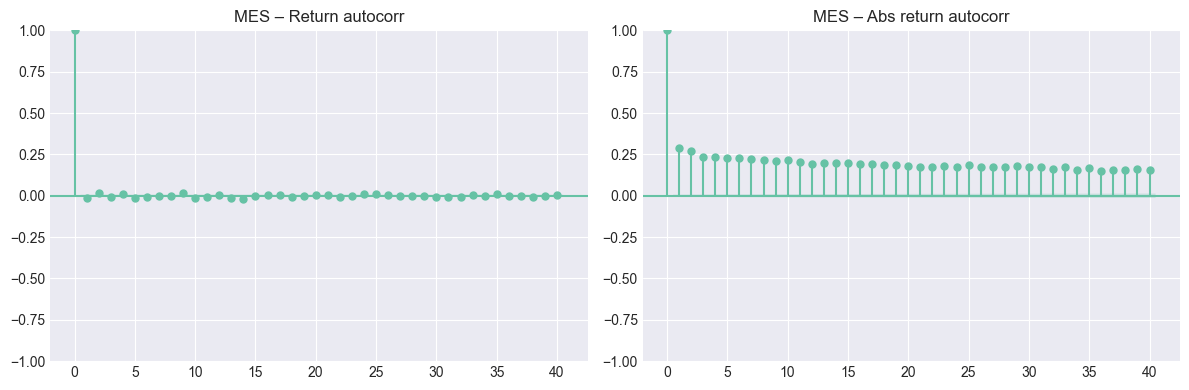

Ljung‑Box p‑values (lags 1-10):
 [2.31302745e-05 6.08495780e-11 2.43366381e-11 2.39091305e-13
 1.29312619e-15 1.50296259e-15 4.21175330e-15 1.23989152e-14
 9.21542853e-18 1.87437776e-19]


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
plot_acf(df['return'].dropna(), lags=40, ax=axes[0], title=f'{INSTRUMENT} – Return autocorr')
plot_acf(df['abs_return'].dropna(), lags=40, ax=axes[1], title=f'{INSTRUMENT} – Abs return autocorr')
plt.tight_layout()
plt.show()

from statsmodels.stats.diagnostic import acorr_ljungbox
lb_test = acorr_ljungbox(df['return'].dropna(), lags=10, return_df=True)
print("Ljung‑Box p‑values (lags 1-10):\n", lb_test['lb_pvalue'].values)

## 4. Intraday seasonality

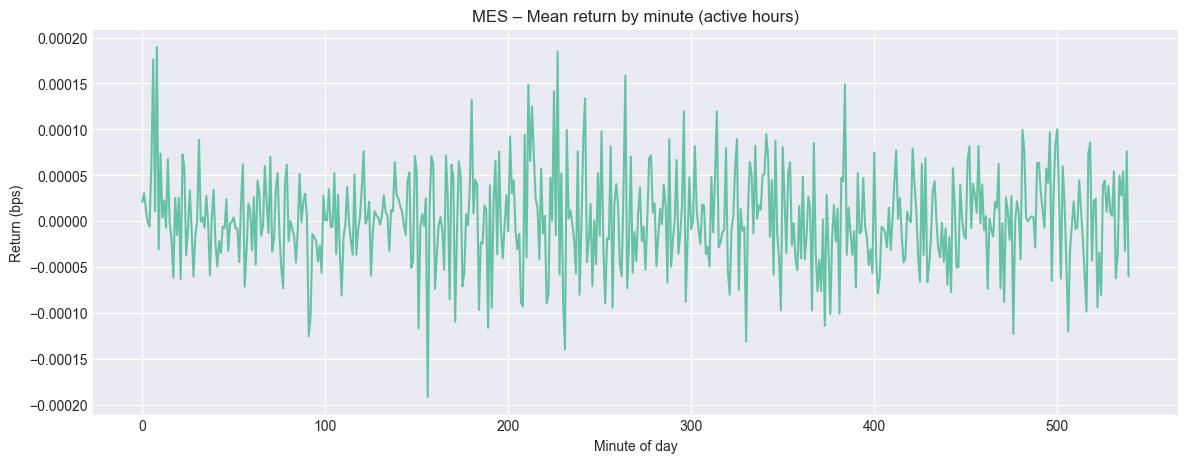

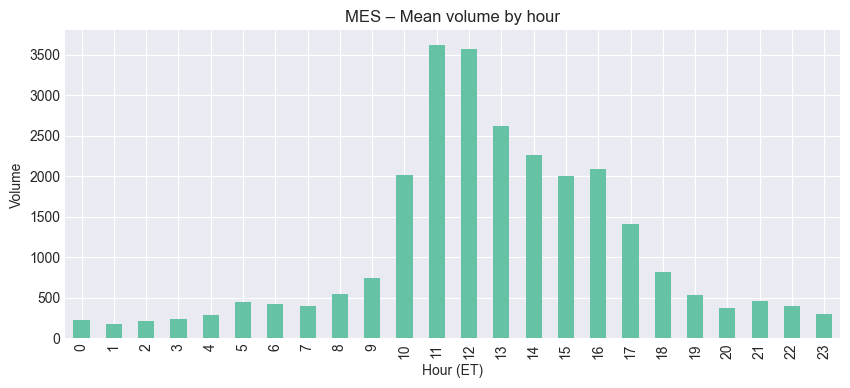

In [10]:
df['hour'] = df.index.hour
df['minute'] = df.index.minute
df['time_of_day'] = df.index.strftime('%H:%M')

active_mask = (df['hour'] >= 8) & (df['hour'] <= 16)
intraday_returns = df[active_mask].groupby('time_of_day')['return'].mean()

plt.figure(figsize=(14,5))
plt.plot(range(len(intraday_returns)), intraday_returns.values)
plt.title(f'{INSTRUMENT} – Mean return by minute (active hours)')
plt.xlabel('Minute of day')
plt.ylabel('Return (bps)')
plt.grid(True)
plt.show()

hourly_vol = df.groupby('hour')['Volume'].mean()
plt.figure(figsize=(10,4))
hourly_vol.plot(kind='bar')
plt.title(f'{INSTRUMENT} – Mean volume by hour')
plt.xlabel('Hour (ET)')
plt.ylabel('Volume')
plt.show()

## 5. Gap behaviour

Gap analysis (mean forward return):
          return_5m  return_10m  return_20m  count
gap_sign                                          
-1         0.000256    0.000228    0.000329     17
 0         0.000003    0.000006    0.000012  87767
 1         0.000606    0.000729    0.000728     14


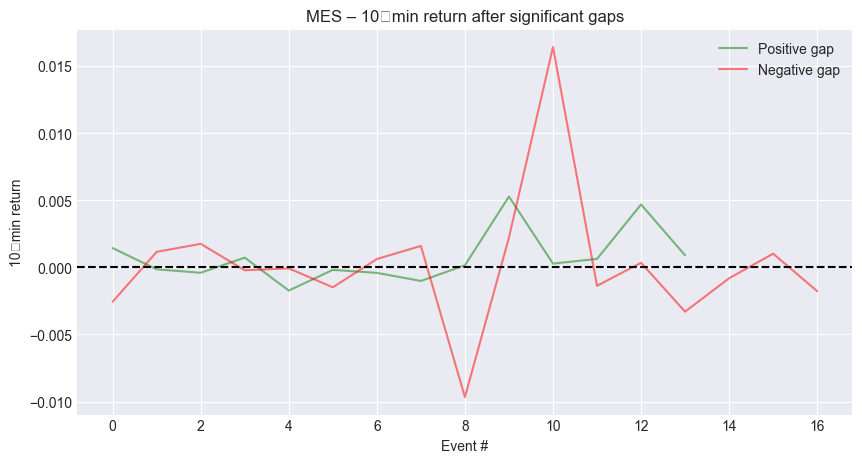

In [11]:
df['gap'] = (df['Open'] - df['Close'].shift(1)) / df['Close'].shift(1)
gap_threshold = 0.0005
df['gap_sign'] = 0
df.loc[df['gap'] > gap_threshold, 'gap_sign'] = 1
df.loc[df['gap'] < -gap_threshold, 'gap_sign'] = -1

for fwd in [5, 10, 20]:
    df[f'return_{fwd}m'] = df['Close'].shift(-fwd) / df['Open'] - 1

gap_analysis = df.groupby('gap_sign').agg({
    'return_5m': 'mean', 'return_10m': 'mean', 'return_20m': 'mean', 'gap': 'count'
}).rename(columns={'gap': 'count'})
print("Gap analysis (mean forward return):")
print(gap_analysis)

significant_gaps = df[df['gap'].abs() > gap_threshold].copy()
plt.figure(figsize=(10,5))
for sign, color, label in [(1, 'green', 'Positive gap'), (-1, 'red', 'Negative gap')]:
    subset = significant_gaps[significant_gaps['gap_sign'] == sign]
    if len(subset) > 10:
        plt.plot(subset['return_10m'].values, color=color, alpha=0.5, label=label)
plt.axhline(y=0, color='black', linestyle='--')
plt.title(f'{INSTRUMENT} – 10‑min return after significant gaps')
plt.xlabel('Event #')
plt.ylabel('10‑min return')
plt.legend()
plt.show()

## 6. Volume anomalies

In [12]:
df['high_vol'] = df['volume_zscore'] > 1.5
forward_after_highvol = df[df['high_vol']]['return_10m'].describe()
print("10‑min return after high volume:\n", forward_after_highvol)

baseline = df[~df['high_vol']]['return_10m'].mean()
highvol_mean = df[df['high_vol']]['return_10m'].mean()
print(f"Baseline 10‑min return: {baseline*100:.3f}%")
print(f"After high volume:       {highvol_mean*100:.3f}%")

10‑min return after high volume:
 count    7917.000000
mean        0.000036
std         0.001175
min        -0.011038
25%        -0.000434
50%         0.000036
75%         0.000460
max         0.032679
Name: return_10m, dtype: float64
Baseline 10‑min return: 0.000%
After high volume:       0.004%


## 7. Volatility regimes

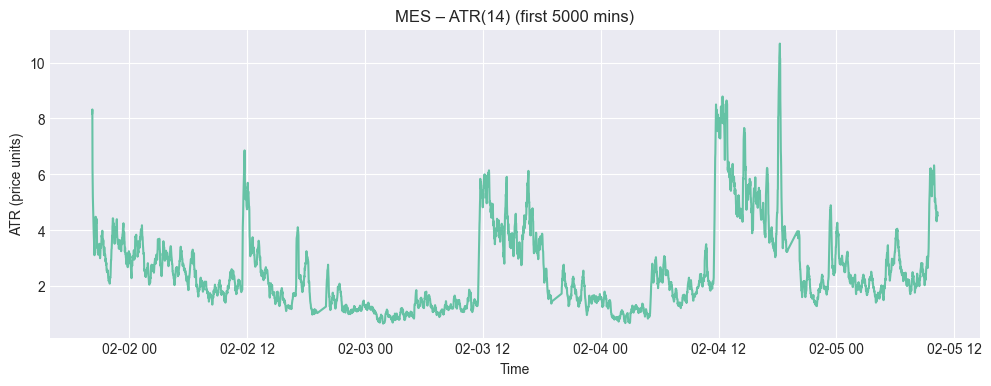

Average 10‑min return by volatility regime:
  Low vol:  -0.000%
  High vol: 0.002%


In [13]:
plt.figure(figsize=(12,4))
plt.plot(df.index[:5000], df['ATR14'].iloc[:5000])
plt.title(f'{INSTRUMENT} – ATR(14) (first 5000 mins)')
plt.ylabel('ATR (price units)')
plt.xlabel('Time')
plt.show()

median_atr = df['ATR14'].median()
df['high_volatility'] = df['ATR14'] > median_atr
vol_regime_ret = df.groupby('high_volatility')['return_10m'].mean()
print("Average 10‑min return by volatility regime:")
print(f"  Low vol:  {vol_regime_ret[False]*100:.3f}%")
print(f"  High vol: {vol_regime_ret[True]*100:.3f}%")

## 8. Summary table

In [14]:
summary = {
    'Instrument': INSTRUMENT,
    'Rows': len(df),
    'Mean return (1m) %': df['return'].mean() * 100,
    'Std return (1m) %': df['return'].std() * 100,
    'Mean volume': df['Volume'].mean(),
    'Mean ATR14': df['ATR14'].mean(),
    'Gap freq (>0.05%) %': (df['gap'].abs() > 0.0005).mean() * 100,
    'Mean 10m return after gap >0.05%': df[df['gap'].abs() > 0.0005]['return_10m'].mean(),
    'Mean 10m return after high vol': df[df['high_vol']]['return_10m'].mean(),
}
pd.DataFrame([summary]).T

,0
Instrument,MES
Rows,87799
Mean return (1m) %,0.000051
Std return (1m) %,0.03101
Mean volume,1096.809531
Mean ATR14,2.508687
Gap freq (>0.05%) %,0.035308
Mean 10m return after gap >0.05%,0.000454
Mean 10m return after high vol,0.000036


### 🔍 Observations & hypotheses

- **Autocorrelation:**  
- **Intraday pattern:**  
- **Gaps:**  
- **Volume:**  
- **Edge ideas:** 